# 03 — 10-fold speaker-independent CNN training and final test

This notebook trains a fresh CNN in each of the 10 speaker-grouped folds. It reports fold-wise metrics and their mean and standard deviation. It then trains one final CNN on the complete outer training partition and evaluates it once on the untouched final test speakers.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import json

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

SEED = 42
EPOCHS = 50
BATCH_SIZE = 32
OUT = Path("anu_revision_output")
OUT.mkdir(exist_ok=True)

np.random.seed(SEED)
tf.random.set_seed(SEED)

data = np.load(OUT / "speaker_split_mfcc_10fold.npz", allow_pickle=True)
X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]
fold_assignments = data["fold_assignments"]
classes = data["classes"].astype(str)

print("Training:", X_train.shape, "Final test:", X_test.shape)
print("Number of folds:", len(np.unique(fold_assignments)))

Training: (3522, 20, 40, 1) Final test: (918, 20, 40, 1)
Number of folds: 10


In [2]:
def build_cnn(input_shape, number_of_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),

        tf.keras.layers.Conv2D(32, (3, 3), padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(64, (3, 3), padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(128, (3, 3), padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),

        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(number_of_classes, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def make_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=0.00001
        )
    ]

In [3]:
# Run 10-fold cross-validation. Each fold gets a newly initialized model.
fold_rows = []
best_epochs = []
fold_histories = []

for fold in range(1, 11):
    print(f"\n========== FOLD {fold}/10 ==========")

    train_mask = fold_assignments != fold
    val_mask = fold_assignments == fold

    X_fit, y_fit = X_train[train_mask], y_train[train_mask]
    X_val, y_val = X_train[val_mask], y_train[val_mask]

    model = build_cnn(X_train.shape[1:], len(classes))

    history = model.fit(
        X_fit,
        y_fit,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=make_callbacks(),
        shuffle=True,
        verbose=1
    )

    val_probabilities = model.predict(X_val, verbose=0)
    val_predictions = val_probabilities.argmax(axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, val_predictions, average="macro", zero_division=0
    )
    accuracy = accuracy_score(y_val, val_predictions)

    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    best_epochs.append(best_epoch)
    fold_histories.append(history.history)

    fold_rows.append({
        "Fold": fold,
        "Train files": int(train_mask.sum()),
        "Validation files": int(val_mask.sum()),
        "Best epoch": best_epoch,
        "Accuracy": accuracy,
        "Macro precision": precision,
        "Macro recall": recall,
        "Macro F1": f1
    })

    model.save(OUT / f"cnn_10fold_fold_{fold:02d}.keras")
    tf.keras.backend.clear_session()

fold_results = pd.DataFrame(fold_rows)
display(fold_results)
fold_results.to_csv(OUT / "cnn_10fold_fold_results.csv", index=False)

summary = fold_results[["Accuracy", "Macro precision", "Macro recall", "Macro F1"]].agg(
    ["mean", "std"]
).T
display(summary)
summary.to_csv(OUT / "cnn_10fold_summary.csv")

print("Mean best epoch:", np.mean(best_epochs))
print("Median best epoch:", int(np.median(best_epochs)))


========== FOLD 1/10 ==========
Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.1229 - loss: 2.5824 - val_accuracy: 0.0862 - val_loss: 2.6353 - learning_rate: 5.0000e-04
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.2344 - loss: 2.3545 - val_accuracy: 0.0891 - val_loss: 2.6204 - learning_rate: 5.0000e-04
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3132 - loss: 2.1137 - val_accuracy: 0.1753 - val_loss: 2.5470 - learning_rate: 5.0000e-04
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.3765 - loss: 1.8810 - val_accuracy: 0.1609 - val_loss: 2.4348 - learning_rate: 5.0000e-04
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.4354 - loss: 1.6812 - val_accuracy: 0.2931 - val_loss: 2.2350 - learning_rate: 5.0000e-04
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.4773 - loss: 1.5263 - val_accuracy: 0.2902 - val_loss: 2.0640 - learning_rate: 5.0000e-04
Epoch 7/50
100/100 ━━━━━━

,Fold,Train files,Validation files,Best epoch,Accuracy,Macro precision,Macro recall,Macro F1
0,1,3174,348,24,0.477011,0.538038,0.488095,0.470997
1,2,3108,414,17,0.463768,0.474222,0.463690,0.447536
2,3,3192,330,22,0.406061,0.439927,0.406746,0.401064
3,4,3192,330,30,0.596970,0.574799,0.604167,0.578191
4,5,3180,342,26,0.698830,0.706434,0.699405,0.688932
5,6,3192,330,10,0.396970,0.464367,0.395833,0.384305
6,7,3180,342,17,0.535088,0.586745,0.533333,0.523310
7,8,3108,414,10,0.502415,0.612833,0.506548,0.494852
8,9,3186,336,14,0.544643,0.548704,0.544643,0.536401
9,10,3186,336,36,0.532738,0.569594,0.532738,0.520049


,mean,std
Accuracy,0.515449,0.089525
Macro precision,0.551566,0.078938
Macro recall,0.517520,0.089919
Macro F1,0.504564,0.088609


Mean best epoch: 20.6
Median best epoch: 19


In [4]:
# Train final CNN on all outer-training speakers.
# The epoch count is the median best epoch selected within cross-validation.
final_epochs = max(1, int(np.median(best_epochs)))
print("Final training epochs:", final_epochs)

final_model = build_cnn(X_train.shape[1:], len(classes))
final_history = final_model.fit(
    X_train,
    y_train,
    epochs=final_epochs,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=1
)

final_probabilities = final_model.predict(X_test, verbose=0)
final_predictions = final_probabilities.argmax(axis=1)

test_precision, test_recall, test_f1, _ = precision_recall_fscore_support(
    y_test, final_predictions, average="macro", zero_division=0
)
test_accuracy = accuracy_score(y_test, final_predictions)

print("Final held-out speaker test accuracy:", test_accuracy)
print("Macro precision:", test_precision)
print("Macro recall:", test_recall)
print("Macro F1:", test_f1)
print(classification_report(
    y_test, final_predictions, target_names=classes, zero_division=0
))

Final training epochs: 19
Epoch 1/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.1124 - loss: 2.5904
Epoch 2/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.2183 - loss: 2.3717
Epoch 3/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.2748 - loss: 2.1785
Epoch 4/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.3353 - loss: 1.9902
Epoch 5/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.3930 - loss: 1.8064
Epoch 6/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.4534 - loss: 1.6242
Epoch 7/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5037 - loss: 1.4834
Epoch 8/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5361 - loss: 1.3540
Epoch 9/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5662 - loss: 1.2513
Epoch 10/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5755 - loss: 1.2061
Epoch 11/19
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5997 - loss: 1.1310
Epoch 12/19
111

,Accuracy,Macro precision,Macro recall,Macro F1,Test files,Final training epochs
0,0.263617,0.524371,0.262121,0.21324,918,19


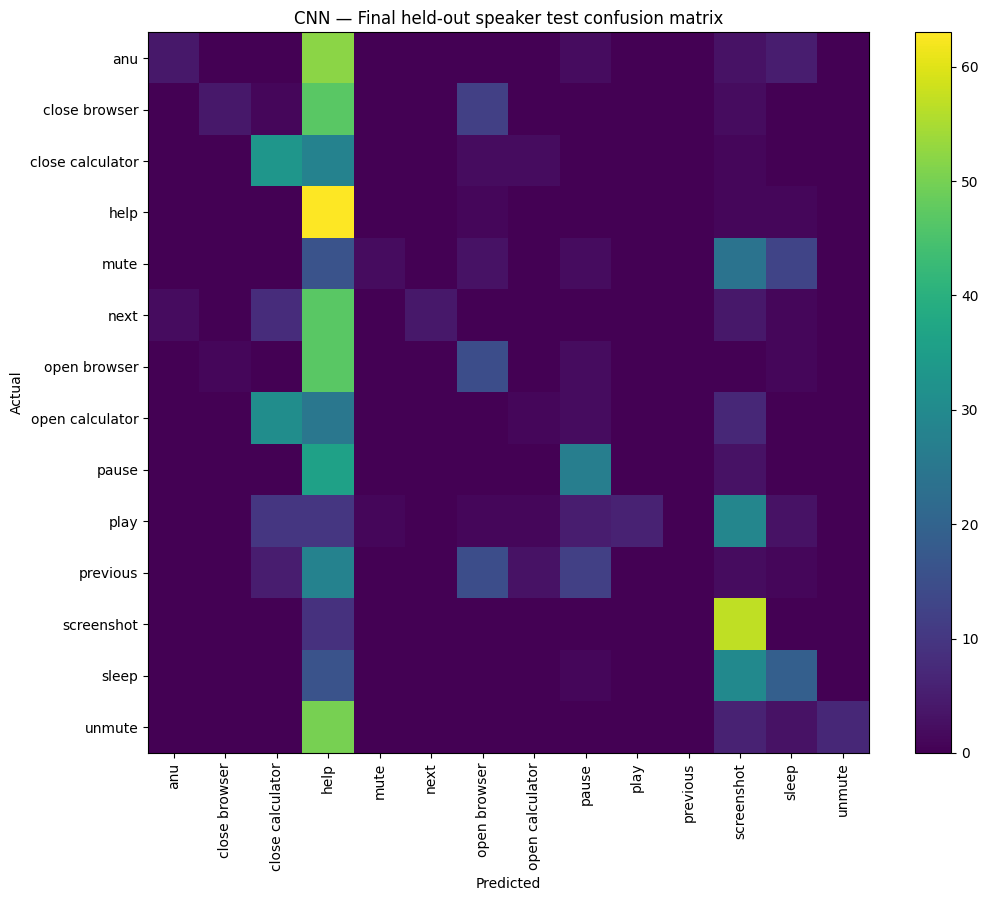

In [5]:
# Save final model, test predictions, confusion matrix, and final-test metrics.
final_model.save(OUT / "anu_cnn_10fold_final.keras")

pd.DataFrame({
    "true": classes[y_test],
    "predicted": classes[final_predictions]
}).to_csv(OUT / "cnn_10fold_final_test_predictions.csv", index=False)

test_metrics = pd.DataFrame([{
    "Accuracy": test_accuracy,
    "Macro precision": test_precision,
    "Macro recall": test_recall,
    "Macro F1": test_f1,
    "Test files": len(y_test),
    "Final training epochs": final_epochs
}])
test_metrics.to_csv(OUT / "cnn_10fold_final_test_metrics.csv", index=False)
display(test_metrics)

cm = confusion_matrix(y_test, final_predictions)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm)
ax.set_xticks(range(len(classes)), classes, rotation=90)
ax.set_yticks(range(len(classes)), classes)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("CNN — Final held-out speaker test confusion matrix")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(OUT / "cnn_10fold_final_confusion_matrix.png", dpi=200)
plt.show()

In [6]:
# Save fold-wise training histories for convergence inspection.
history_rows = []
for fold_number, history in enumerate(fold_histories, start=1):
    for epoch_index in range(len(history["loss"])):
        history_rows.append({
            "Fold": fold_number,
            "Epoch": epoch_index + 1,
            "Loss": history["loss"][epoch_index],
            "Accuracy": history["accuracy"][epoch_index],
            "Validation loss": history["val_loss"][epoch_index],
            "Validation accuracy": history["val_accuracy"][epoch_index]
        })

pd.DataFrame(history_rows).to_csv(
    OUT / "cnn_10fold_training_histories.csv", index=False
)
print("10-fold CNN outputs saved in:", OUT.resolve())

10-fold CNN outputs saved in: C:\Users\ADMIN\Desktop\Sukriti\VIT\SL\AnuAssistant\Anu_Revision_Notebooks\anu_revision_output


### Outputs

- `cnn_10fold_fold_results.csv` — each fold's validation metrics.
- `cnn_10fold_summary.csv` — mean and standard deviation across folds.
- `anu_cnn_10fold_final.keras` — final CNN trained on all outer-training speakers.
- `cnn_10fold_final_test_metrics.csv` — final untouched test metrics.
- `cnn_10fold_final_test_predictions.csv` and confusion matrix — final test outputs.

The 10-fold mean is the cross-validation estimate. The separate final-test score is the performance on the reserved speakers. Report them separately.